# PaySim Dataset - Fraud Detection Model

This notebook trains and evaluates machine learning models for fraud detection using the preprocessed PaySim dataset.

Models used:

- Logistic Regression
- Random Forest
- XGBoost

Since fraudulent transactions are highly imbalanced, model performance will be evaluated using:

- Precision
- Recall
- F1-Score
- ROC-AUC
- PR-AUC
- Confusion Matrix

The best-performing model will be saved for use in the FinShield application.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

import joblib
import os

In [4]:
%conda install -c conda-forge py-xgboost -y

2 channel Terms of Service accepted
Retrieving notices: done
Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 25.11.1
    latest version: 26.7.2

Please update conda by running

    $ conda update -n base -c defaults conda



## Package Plan ##

  environment location: /opt/anaconda3/envs/eeg_pd

  added / updated specs:
    - py-xgboost


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    _openmp_mutex-4.5          |       8_kmp_llvm           8 KB  conda-forge
    blas-2.311                 |         openblas          18 KB  conda-forge
    blas-devel-3.11.0          |11_h11c0a38_openblas          18 KB  conda-forge
    ca-certificates-2026.7.22  |       hbd8a1cb_0         129 KB  conda-forge
    cloudpickle-3.1.2          |     pyhcf101f3_1          27 KB  conda-forge
    joblib-1.6

In [1]:
from xgboost import XGBClassifier

In [ ]:
import os

processed_file = "../data/paysim_processed.csv"

print(
    "Processed file exists:",
    os.path.exists(processed_file)
)

Processed file exists: True


In [10]:
sample = pd.read_csv(
    processed_file,
    nrows=10000
)

print("Sample shape:", sample.shape)

sample.head()

Sample shape: (10000, 19)


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFlaggedFraud,origin_balance_change,destination_balance_change,origin_error,destination_error,amount_to_origin_balance,amount_to_destination_balance,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,isFraud
0,1,9839.64,170136.0,160296.36,0.0,0.0,0,9839.64,0.0,-1.455192e-11,9839.64,0.057834,9839.640000,0,0,0,1,0,0
1,1,1864.28,21249.0,19384.72,0.0,0.0,0,1864.28,0.0,1.136868e-12,1864.28,0.087731,1864.280000,0,0,0,1,0,0
2,1,181.00,181.0,0.00,0.0,0.0,0,181.00,0.0,0.000000e+00,181.00,0.994505,181.000000,0,0,0,0,1,1
3,1,181.00,181.0,0.00,21182.0,0.0,0,181.00,-21182.0,0.000000e+00,21363.00,0.994505,0.008545,0,1,0,0,0,1
4,1,11668.14,41554.0,29885.86,0.0,0.0,0,11668.14,0.0,0.000000e+00,11668.14,0.280788,11668.140000,0,0,0,1,0,0


In [11]:
sample.columns.tolist()

['step',
 'amount',
 'oldbalanceOrg',
 'newbalanceOrig',
 'oldbalanceDest',
 'newbalanceDest',
 'isFlaggedFraud',
 'origin_balance_change',
 'destination_balance_change',
 'origin_error',
 'destination_error',
 'amount_to_origin_balance',
 'amount_to_destination_balance',
 'type_CASH_IN',
 'type_CASH_OUT',
 'type_DEBIT',
 'type_PAYMENT',
 'type_TRANSFER',
 'isFraud']

In [12]:
target_column = "isFraud"

feature_columns = [
    column
    for column in sample.columns
    if column != target_column
]

print("Number of features:", len(feature_columns))
print("\nFeatures:")

for feature in feature_columns:
    print(feature)

Number of features: 18

Features:
step
amount
oldbalanceOrg
newbalanceOrig
oldbalanceDest
newbalanceDest
isFlaggedFraud
origin_balance_change
destination_balance_change
origin_error
destination_error
amount_to_origin_balance
amount_to_destination_balance
type_CASH_IN
type_CASH_OUT
type_DEBIT
type_PAYMENT
type_TRANSFER


In [13]:
sample[target_column].value_counts()

isFraud
0    9932
1      68
Name: count, dtype: int64

In [15]:
CHUNK_SIZE = 500000

X_chunks = []
y_chunks = []

for chunk_number, chunk in enumerate(
    pd.read_csv(
        processed_file,
        chunksize=CHUNK_SIZE
    ),
    start=1
):
    
    print(
        f"Loading chunk {chunk_number}:",
        chunk.shape
    )
    
    X_chunks.append(
        chunk[feature_columns]
    )
    
    y_chunks.append(
        chunk[target_column]
    )

Loading chunk 1: (500000, 19)
Loading chunk 2: (500000, 19)
Loading chunk 3: (500000, 19)
Loading chunk 4: (500000, 19)
Loading chunk 5: (500000, 19)
Loading chunk 6: (500000, 19)
Loading chunk 7: (500000, 19)
Loading chunk 8: (500000, 19)
Loading chunk 9: (500000, 19)
Loading chunk 10: (500000, 19)
Loading chunk 11: (500000, 19)
Loading chunk 12: (500000, 19)
Loading chunk 13: (362620, 19)


In [16]:
X = pd.concat(
    X_chunks,
    ignore_index=True
)

y = pd.concat(
    y_chunks,
    ignore_index=True
)

In [17]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (6362620, 18)
y shape: (6362620,)


In [18]:
del X_chunks
del y_chunks

In [19]:
print(
    "Missing values:",
    X.isnull().sum().sum()
)

print(
    "Infinite values:",
    np.isinf(X.select_dtypes(include=np.number)).sum().sum()
)

Missing values: 0
Infinite values: 0


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [21]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5090096
Testing samples: 1272524


In [22]:
print("Training distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training distribution:
isFraud
0    5083526
1       6570
Name: count, dtype: int64

Testing distribution:
isFraud
0    1270881
1       1643
Name: count, dtype: int64


In [23]:
print(
    "\nTraining percentage:"
)

print(
    y_train.value_counts(
        normalize=True
    ) * 100
)


Training percentage:
isFraud
0    99.870926
1     0.129074
Name: proportion, dtype: float64


In [24]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

In [25]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print(
    "Negative samples:",
    negative_count
)

print(
    "Positive samples:",
    positive_count
)

print(
    "Scale positive weight:",
    scale_pos_weight
)

Negative samples: 5083526
Positive samples: 6570
Scale positive weight: 773.7482496194825


In [26]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [27]:
lr_predictions = logistic_model.predict(
    X_test_scaled
)

lr_probabilities = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

In [28]:
print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=[
            "Non-Fraud",
            "Fraud"
        ]
    )
)

              precision    recall  f1-score   support

   Non-Fraud       1.00      0.96      0.98   1270881
       Fraud       0.03      0.98      0.07      1643

    accuracy                           0.96   1272524
   macro avg       0.52      0.97      0.52   1272524
weighted avg       1.00      0.96      0.98   1272524



In [29]:
lr_precision = precision_score(
    y_test,
    lr_predictions
)

lr_recall = recall_score(
    y_test,
    lr_predictions
)

lr_f1 = f1_score(
    y_test,
    lr_predictions
)

lr_roc_auc = roc_auc_score(
    y_test,
    lr_probabilities
)

lr_pr_auc = average_precision_score(
    y_test,
    lr_probabilities
)

print("Logistic Regression")
print("-------------------")
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1-Score:", lr_f1)
print("ROC-AUC:", lr_roc_auc)
print("PR-AUC:", lr_pr_auc)

Logistic Regression
-------------------
Precision: 0.03374644113213867
Recall: 0.9811320754716981
F1-Score: 0.06524862884782741
ROC-AUC: 0.9962034665881849
PR-AUC: 0.6187998412526717


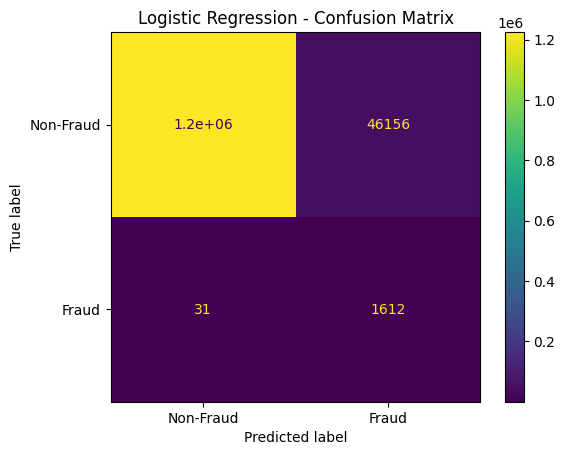

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    display_labels=[
        "Non-Fraud",
        "Fraud"
    ]
)

plt.title(
    "Logistic Regression - Confusion Matrix"
)

plt.show()

In [31]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest training completed.")

Random Forest training completed.


In [32]:
rf_predictions = random_forest_model.predict(
    X_test
)

rf_probabilities = random_forest_model.predict_proba(
    X_test
)[:, 1]

In [33]:
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=[
            "Non-Fraud",
            "Fraud"
        ]
    )
)

              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00   1270881
       Fraud       1.00      1.00      1.00      1643

    accuracy                           1.00   1272524
   macro avg       1.00      1.00      1.00   1272524
weighted avg       1.00      1.00      1.00   1272524



In [34]:
rf_precision = precision_score(
    y_test,
    rf_predictions
)

rf_recall = recall_score(
    y_test,
    rf_predictions
)

rf_f1 = f1_score(
    y_test,
    rf_predictions
)

rf_roc_auc = roc_auc_score(
    y_test,
    rf_probabilities
)

rf_pr_auc = average_precision_score(
    y_test,
    rf_probabilities
)

print("Random Forest")
print("-------------")
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1-Score:", rf_f1)
print("ROC-AUC:", rf_roc_auc)
print("PR-AUC:", rf_pr_auc)

Random Forest
-------------
Precision: 1.0
Recall: 0.9975654290931223
F1-Score: 0.9987812309567337
ROC-AUC: 0.9990864818064016
PR-AUC: 0.99810242725087


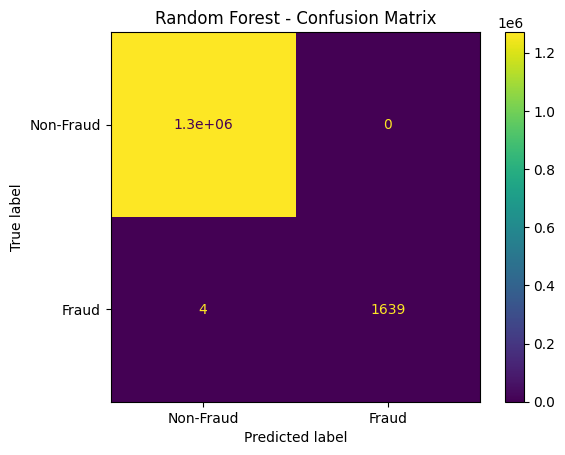

In [35]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=[
        "Non-Fraud",
        "Fraud"
    ]
)

plt.title(
    "Random Forest - Confusion Matrix"
)

plt.show()

In [36]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")

XGBoost training completed.


In [37]:
xgb_predictions = xgb_model.predict(
    X_test
)

xgb_probabilities = xgb_model.predict_proba(
    X_test
)[:, 1]

In [38]:
print(
    classification_report(
        y_test,
        xgb_predictions,
        target_names=[
            "Non-Fraud",
            "Fraud"
        ]
    )
)

              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00   1270881
       Fraud       0.88      1.00      0.93      1643

    accuracy                           1.00   1272524
   macro avg       0.94      1.00      0.97   1272524
weighted avg       1.00      1.00      1.00   1272524



In [39]:
xgb_precision = precision_score(
    y_test,
    xgb_predictions
)

xgb_recall = recall_score(
    y_test,
    xgb_predictions
)

xgb_f1 = f1_score(
    y_test,
    xgb_predictions
)

xgb_roc_auc = roc_auc_score(
    y_test,
    xgb_probabilities
)

xgb_pr_auc = average_precision_score(
    y_test,
    xgb_probabilities
)

print("XGBoost")
print("-------")
print("Precision:", xgb_precision)
print("Recall:", xgb_recall)
print("F1-Score:", xgb_f1)
print("ROC-AUC:", xgb_roc_auc)
print("PR-AUC:", xgb_pr_auc)

XGBoost
-------
Precision: 0.8754676643506146
Recall: 0.996956786366403
F1-Score: 0.9322709163346613
ROC-AUC: 0.9994488963980309
PR-AUC: 0.9940683048227454


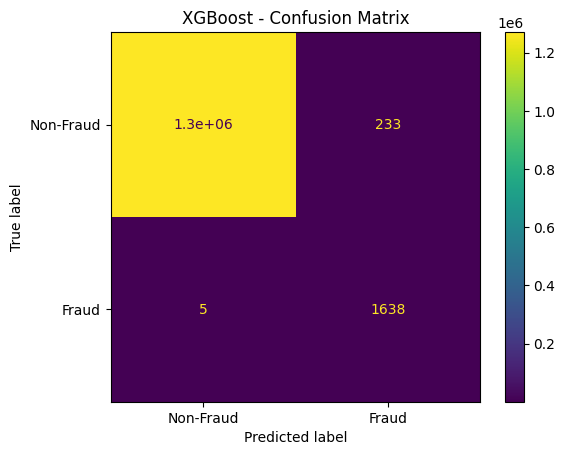

In [40]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_predictions,
    display_labels=[
        "Non-Fraud",
        "Fraud"
    ]
)

plt.title(
    "XGBoost - Confusion Matrix"
)

plt.show()

In [41]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    
    "Precision": [
        lr_precision,
        rf_precision,
        xgb_precision
    ],
    
    "Recall": [
        lr_recall,
        rf_recall,
        xgb_recall
    ],
    
    "F1-Score": [
        lr_f1,
        rf_f1,
        xgb_f1
    ],
    
    "ROC-AUC": [
        lr_roc_auc,
        rf_roc_auc,
        xgb_roc_auc
    ],
    
    "PR-AUC": [
        lr_pr_auc,
        rf_pr_auc,
        xgb_pr_auc
    ]
})

results

,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.033746,0.981132,0.065249,0.996203,0.618800
1,Random Forest,1.000000,0.997565,0.998781,0.999086,0.998102
2,XGBoost,0.875468,0.996957,0.932271,0.999449,0.994068


In [42]:
results.sort_values(
    "F1-Score",
    ascending=False
)

,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
1,Random Forest,1.000000,0.997565,0.998781,0.999086,0.998102
2,XGBoost,0.875468,0.996957,0.932271,0.999449,0.994068
0,Logistic Regression,0.033746,0.981132,0.065249,0.996203,0.618800


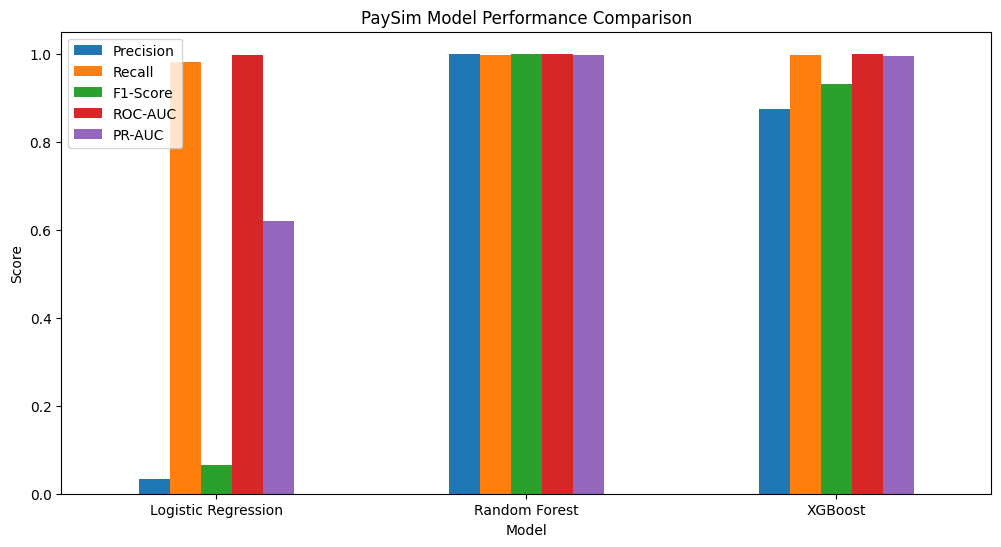

In [43]:
results.set_index(
    "Model"
)[
    [
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "PaySim Model Performance Comparison"
)

plt.ylabel("Score")
plt.xticks(rotation=0)

plt.show()

In [44]:
lr_fpr, lr_tpr, _ = roc_curve(
    y_test,
    lr_probabilities
)

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_probabilities
)

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_probabilities
)

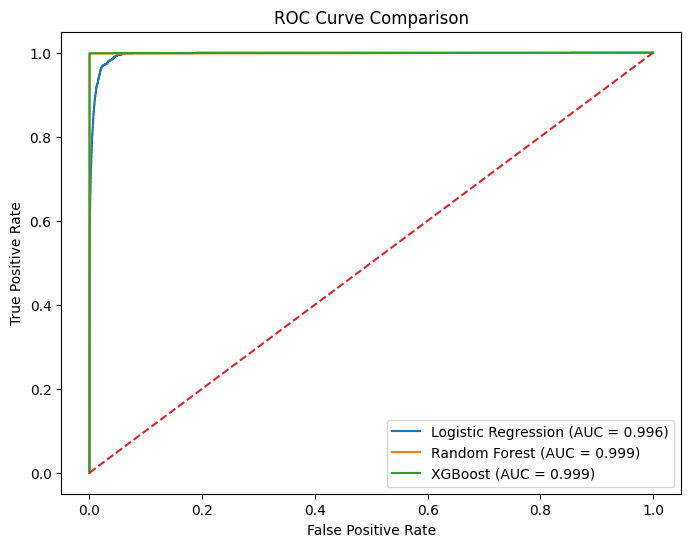

In [45]:
plt.figure(figsize=(8, 6))

plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (AUC = {lr_roc_auc:.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_roc_auc:.3f})"
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost (AUC = {xgb_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.show()

In [46]:
lr_precision_curve, lr_recall_curve, _ = precision_recall_curve(
    y_test,
    lr_probabilities
)

rf_precision_curve, rf_recall_curve, _ = precision_recall_curve(
    y_test,
    rf_probabilities
)

xgb_precision_curve, xgb_recall_curve, _ = precision_recall_curve(
    y_test,
    xgb_probabilities
)

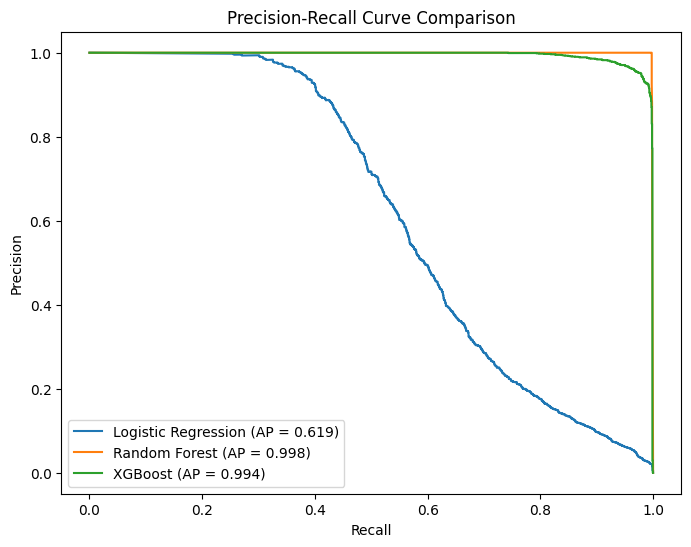

In [47]:
plt.figure(figsize=(8, 6))

plt.plot(
    lr_recall_curve,
    lr_precision_curve,
    label=f"Logistic Regression (AP = {lr_pr_auc:.3f})"
)

plt.plot(
    rf_recall_curve,
    rf_precision_curve,
    label=f"Random Forest (AP = {rf_pr_auc:.3f})"
)

plt.plot(
    xgb_recall_curve,
    xgb_precision_curve,
    label=f"XGBoost (AP = {xgb_pr_auc:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve Comparison"
)

plt.legend()

plt.show()

In [48]:
feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=feature_columns
).sort_values(
    ascending=False
)

feature_importance.head(15)

newbalanceOrig                   0.407965
origin_error                     0.388813
origin_balance_change            0.088993
amount_to_origin_balance         0.030645
isFlaggedFraud                   0.016938
type_PAYMENT                     0.016769
amount                           0.011901
type_TRANSFER                    0.010976
destination_error                0.006655
type_CASH_OUT                    0.005320
amount_to_destination_balance    0.003084
newbalanceDest                   0.002964
oldbalanceOrg                    0.002958
oldbalanceDest                   0.001767
destination_balance_change       0.001278
dtype: float32

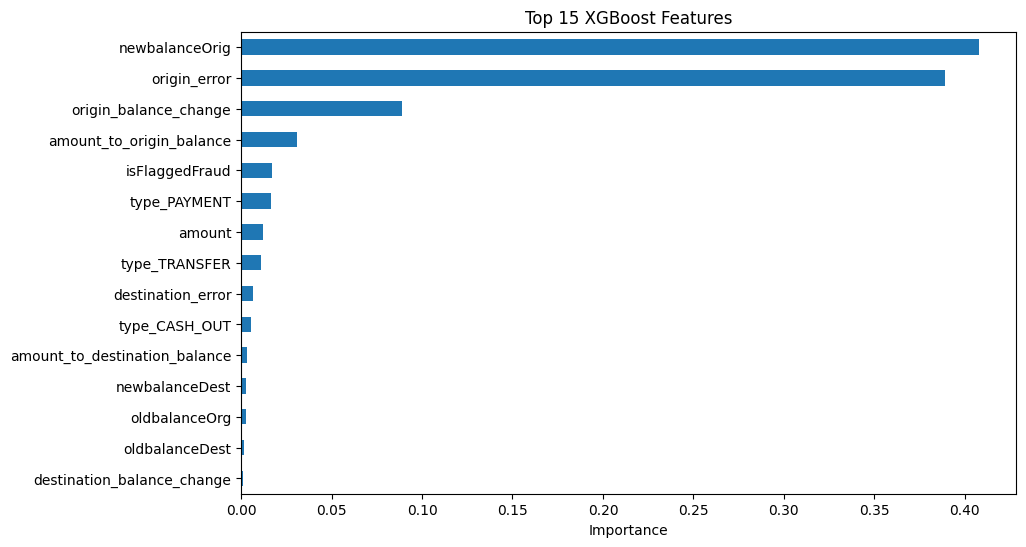

In [49]:
feature_importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title(
    "Top 15 XGBoost Features"
)

plt.xlabel("Importance")

plt.show()

In [50]:
best_model_name = results.sort_values(
    "F1-Score",
    ascending=False
).iloc[0]["Model"]

print(
    "Best model based on F1-Score:",
    best_model_name
)

Best model based on F1-Score: Random Forest


In [51]:
models_dir = "../models"

os.makedirs(
    models_dir,
    exist_ok=True
)

print(
    "Models directory ready:",
    models_dir
)

Models directory ready: ../models


In [52]:
joblib.dump(
    xgb_model,
    "../models/paysim_xgboost.pkl"
)

print("XGBoost model saved.")

XGBoost model saved.


In [53]:
joblib.dump(
    random_forest_model,
    "../models/paysim_random_forest.pkl"
)

print("Random Forest model saved.")

Random Forest model saved.


In [54]:
joblib.dump(
    logistic_model,
    "../models/paysim_logistic_regression.pkl"
)

joblib.dump(
    scaler,
    "../models/paysim_scaler.pkl"
)

print("Logistic Regression model and scaler saved.")

Logistic Regression model and scaler saved.


In [56]:
import os

out_path = "../reports/paysim_model_results.csv"
os.makedirs(os.path.dirname(out_path), exist_ok=True)

results.to_csv(out_path, index=False)

print("Model results saved.")

Model results saved.


In [57]:
print("======================================")
print("       PAYSIM MODEL SUMMARY")
print("======================================")

print(
    "\nBest model:",
    best_model_name
)

print("\nModel Performance:")
print(
    results.sort_values(
        "F1-Score",
        ascending=False
    ).to_string(
        index=False
    )
)

print("\nModels saved in:")
print("../models/")

print("\nResults saved in:")
print("../reports/")

       PAYSIM MODEL SUMMARY

Best model: Random Forest

Model Performance:
              Model  Precision   Recall  F1-Score  ROC-AUC   PR-AUC
      Random Forest   1.000000 0.997565  0.998781 0.999086 0.998102
            XGBoost   0.875468 0.996957  0.932271 0.999449 0.994068
Logistic Regression   0.033746 0.981132  0.065249 0.996203 0.618800

Models saved in:
../models/

Results saved in:
../reports/
